# Análisis de sentimiento en reseñas de clientes — WeLoveReviews

## 1. Objetivos

WeLoveReviews acaba de incorporar un negocio (Harbor House Café) con una puntuación media de **4,5 / 5**. La account manager va a entregarle 500 reseñas escritas y antes quiere una segunda opinión:

> «Necesito saber, en términos simples, cuántas de estas reseñas se leen como positivas, neutrales o negativas — y si esa distribución coincide con su promedio de 4.5 estrellas. Si hay una diferencia, quiero entender de dónde viene antes de ponerlo frente al cliente.»

Este notebook responde a tres preguntas:

1. ¿Qué parte de las 500 reseñas se lee como positiva, neutral o negativa?
2. ¿Ese reparto es coherente con una media de 4,5 estrellas?
3. Si no coincide, ¿la diferencia está en lo que escriben los clientes o en cómo lee el modelo?

No entrenamos nada: usamos un modelo de sentimiento ya entrenado de Hugging Face y comprobamos su resultado contra las estrellas y contra una lectura a mano. El recorrido es: exploración de los datos (2), plan y modelo (3), inferencia (4), desglose frente al 4,5 (5), falsos negativos (6), muestra revisada a mano (7), paso a producción (8) y conclusiones (9). Al final hay un anexo que compara con un segundo modelo.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd

RAW_PATH = Path("../data/raw/reviews.csv")
BUSINESS_AVERAGE = 4.5

pd.set_option("display.max_colwidth", None)

# Estilo común de los gráficos: fondo claro, rejilla fina y un color por serie.
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.bottom": False, "ytick.left": False,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titlepad": 12, "font.size": 10,
    "figure.dpi": 110,
})

## 2. Exploración de los datos (EDA)

Empezamos por lo básico: cuántas filas hay, qué columnas y de qué tipo.

In [2]:
reviews = pd.read_csv(RAW_PATH)
text = reviews["review_text"]

print(f"Filas y columnas: {reviews.shape}")
print(reviews.dtypes.to_string())
reviews.head(3)

Filas y columnas: (500, 3)
review_id      int64
rating         int64
review_text      str


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.


Tres columnas: un identificador, la puntuación en estrellas y el texto. Antes de mirar el contenido comprobamos si falta algo o hay filas repetidas.

In [3]:
quality = pd.Series({
    "valores nulos (todas las columnas)": reviews.isna().sum().sum(),
    "textos vacíos": (text.str.strip() == "").sum(),
    "review_id repetidos": reviews["review_id"].duplicated().sum(),
    "ratings fuera de 1-5": (~reviews["rating"].between(1, 5)).sum(),
    "textos con HTML o URL": text.str.contains(r"<[^>]+>|https?://").sum(),
    "textos con espacios sobrantes": (text != text.str.strip()).sum(),
    "textos repetidos": text.duplicated().sum(),
}, name="filas")
display(quality.to_frame())

repeated = reviews[text.duplicated(keep=False)]
same_rating = repeated.groupby("review_text")["rating"].nunique().eq(1).all()
print(f"Los textos repetidos forman {repeated['review_text'].nunique()} parejas con review_id distinto; "
      f"misma puntuación dentro de cada pareja: {same_rating}")

,filas
valores nulos (todas las columnas),0
textos vacíos,0
review_id repetidos,0
ratings fuera de 1-5,0
textos con HTML o URL,0
textos con espacios sobrantes,0
textos repetidos,7


Los textos repetidos forman 7 parejas con review_id distinto; misma puntuación dentro de cada pareja: True


No falta nada. Lo único llamativo son 7 textos que aparecen dos veces, cada vez con otro `review_id` y la misma puntuación. Seguimos con la distribución de las estrellas, que es contra lo que compararemos el modelo.

Puntuación media: 4.50 | mediana: 5


,reseñas,%
estrellas,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


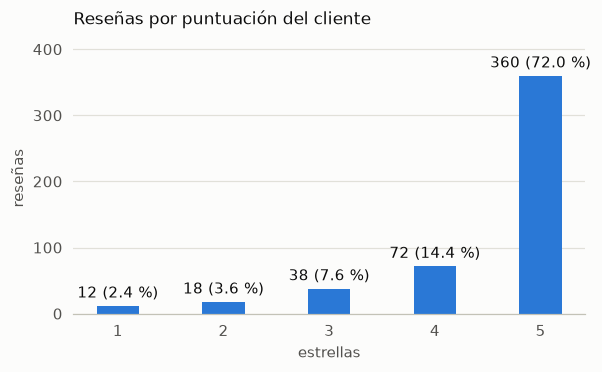

In [4]:
rating_counts = reviews["rating"].value_counts().sort_index()
rating_table = pd.DataFrame({
    "reseñas": rating_counts,
    "%": (rating_counts / len(reviews) * 100).round(1),
})
rating_table.index.name = "estrellas"

print(f"Puntuación media: {reviews['rating'].mean():.2f} | mediana: {reviews['rating'].median():.0f}")
display(rating_table)

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(rating_table.index.astype(str), rating_table["reseñas"], width=0.4, color=BLUE)
ax.bar_label(bars, labels=[f"{n} ({p} %)" for n, p in zip(rating_table["reseñas"], rating_table["%"])], padding=3)
ax.set(title="Reseñas por puntuación del cliente", xlabel="estrellas", ylabel="reseñas", ylim=(0, 410))
plt.show()

La media es exactamente 4,50 y sale de una distribución muy inclinada: casi tres de cada cuatro reseñas tienen 5 estrellas. Ahora la longitud de los textos, que condiciona cómo se pasan al modelo.

,count,mean,std,min,25%,50%,75%,max
caracteres,500.0,170.2,27.1,86.0,155.0,173.0,189.0,230.0
palabras,500.0,29.1,4.8,14.0,26.0,29.0,32.0,42.0


,count,mean,min,max
rating,,,,
1,12,30.2,23,39
2,18,26.4,16,34
3,38,26.8,15,35
4,72,30.5,19,41
5,360,29.2,14,42


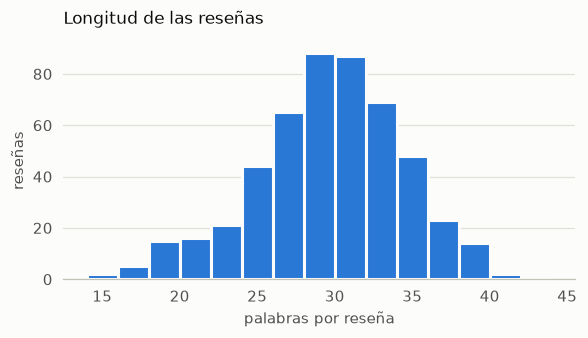

In [5]:
lengths = pd.DataFrame({
    "rating": reviews["rating"],
    "caracteres": text.str.len(),
    "palabras": text.str.split().str.len(),
})
display(lengths[["caracteres", "palabras"]].describe().round(1).T)
display(lengths.groupby("rating")["palabras"].agg(["count", "mean", "min", "max"]).round(1))

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(lengths["palabras"], bins=range(14, 46, 2), color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.set(title="Longitud de las reseñas", xlabel="palabras por reseña", ylabel="reseñas")
plt.show()

Textos cortos y de tamaño parecido en todas las puntuaciones (entre 14 y 42 palabras). Leemos unos cuantos, dos por puntuación.

In [6]:
reviews.groupby("rating").sample(n=2, random_state=7)[["review_id", "rating", "review_text"]]

,review_id,rating,review_text
313,314,1,Regular customer at Harbor House Café here. My eggs came out cold. Nobody checked on us the entire meal. Not sure I'll be returning.
441,442,1,Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
46,47,2,Came to Harbor House Café for a birthday brunch. The portions were way too small for the price. Our server got our order wrong twice. Probably won't recommend it to friends.
490,491,2,Visited Harbor House Café last weekend. My eggs came out cold. Our server got our order wrong twice. Expected a lot more given the reviews.
376,377,3,"The menu is fine but a bit repetitive. Service was fine, nothing memorable. Might give it another shot."
22,23,3,Regular customer at Harbor House Café here. The menu is fine but a bit repetitive. The staff were polite but a bit slow. It's fine for a quick stop.
434,435,4,"Regular customer at Harbor House Café here. Best brunch i've had in months. Service was fine, nothing memorable, but overall a solid experience. Five stars without hesitation."
394,395,4,"The food was absolutely delicious. We waited 25 minutes just to get water, but overall a solid experience. Might give it another shot."
337,338,5,Tried Harbor House Café after seeing it recommended online. The music and decor set the perfect mood. Every dish was bursting with flavor. This is now my go-to spot.
265,266,5,"Grabbed a quick coffee at Harbor House Café this morning. The place has such a cozy, welcoming vibe. Our server remembered our names by the second visit. Reasonably priced for the quality. Already planning my next visit."


Están en inglés, hablan de un mismo local y se repiten frases enteras entre reseñas. Lo medimos partiendo cada reseña en frases.

In [7]:
def split_sentences(review):
    return re.split(r"(?<=[.!?])\s+", review.strip())


sentences = text.apply(split_sentences).explode()
print(f"Frases en total: {len(sentences)} | frases distintas: {sentences.nunique()} | "
      f"frases por reseña: de {sentences.groupby(level=0).size().min()} a {sentences.groupby(level=0).size().max()}")
sentences.value_counts().head(8).rename("apariciones").to_frame()

Frases en total: 2108 | frases distintas: 69 | frases por reseña: de 3 a 5


,apariciones
review_text,
This is now my go-to spot.,92
Will definitely be back!,85
Five stars without hesitation.,84
Came to Harbor House Café for a birthday brunch.,79
Tried Harbor House Café after seeing it recommended online.,76
Already planning my next visit.,75
Regular customer at Harbor House Café here.,74
Grabbed a quick coffee at Harbor House Café this morning.,73


Las 500 reseñas son combinaciones de solo 69 frases. En la muestra también se ven reseñas mixtas: un comentario sobre el servicio seguido de «but overall a solid experience» o «but honestly the food made up for it». Contamos cuántas hay y qué dicen antes del «but».

In [8]:
MIXED_ENDINGS = ["but overall a solid experience", "but honestly the food made up for it"]

mixed = pd.DataFrame({ending: text.str.contains(ending) for ending in MIXED_ENDINGS})
display(mixed.groupby(reviews["rating"]).sum())

complaints = sentences[sentences.str.contains("|".join(MIXED_ENDINGS))].str.split(", but ").str[0]
complaints.value_counts().rename("reseñas").to_frame()

,but overall a solid experience,but honestly the food made up for it
rating,,
1,0,0
2,0,0
3,0,0
4,69,0
5,0,21


,reseñas
review_text,
We waited 25 minutes just to get water,18
The staff seemed annoyed to be there,17
"Service was fine, nothing memorable",17
The staff were polite but a bit slow,16
"Average service, no complaints",12
Our server got our order wrong twice,5
The cashier was rude when i asked about the menu,3
Nobody checked on us the entire meal,2


### Insights

1. **Datos completos:** 500 reseñas, 3 columnas, sin nulos, sin textos vacíos y con `review_id` único.
2. **La referencia es muy positiva:** media de 4,50; el 86,4 % de las reseñas tiene 4–5 estrellas, el 7,6 % tiene 3 y el 6,0 % tiene 1–2. Si el texto dice lo mismo que las estrellas, el modelo debería acercarse a ese reparto.
3. **Textos cortos y en inglés:** entre 14 y 42 palabras. Caben enteros en el modelo, sin recortar ni trocear.
4. **Texto de plantilla:** solo hay 69 frases distintas. Si el modelo lee mal una frase, la leerá mal en todas las reseñas que la lleven, así que los errores serán sistemáticos y se pueden estudiar frase a frase.
5. **Reseñas mixtas:** 90 reseñas con 4–5 estrellas (69 de las 72 de 4 estrellas y 21 de 5) llevan un «pero», siempre sobre el servicio: 61 con una queja clara (esperas, lentitud, trato, pedidos equivocados) y 29 con un servicio «sin más». Son reseñas de servicio, no de producto, y es donde cabe esperar más desacuerdo con el modelo.

### Propuesta de limpieza

No hace falta limpiar:

- No hay nulos, textos vacíos, HTML, URL ni espacios sobrantes que tratar.
- Los 7 textos repetidos se conservan: tienen `review_id` distinto, así que cuentan como reseñas distintas, y quitarlos cambiaría las 500 reseñas y el 4,5 que queremos contrastar.
- No pasamos el texto a minúsculas ni quitamos acentos o puntuación: el tokenizador del modelo ya normaliza lo que necesita.

En el script de producción dejamos una única salvaguarda: quitar espacios al principio y al final y fallar si llega una reseña sin texto.

## 3. Plan de acción y justificación del modelo

Lo que sale de la exploración y lo que hacemos con ello:

| Insight | Decisión |
| --- | --- |
| La referencia son las estrellas (86,4 / 7,6 / 6,0 %) | Clasificar las 500 reseñas y comparar el reparto del modelo con el de las estrellas y con la media de 4,5 |
| Textos cortos, limpios y en inglés | Pasar el texto tal cual, sin limpieza previa |
| Solo 69 frases distintas | Analizar los errores frase a frase, no solo reseña a reseña |
| Reseñas mixtas y vocabulario de servicio | Buscar falsos negativos y revisar a mano una muestra antes de fiarnos del total |

**Modelo:** `nlptown/bert-base-multilingual-uncased-sentiment`. Es el que pide el encargo y encaja con la pregunta: predice una puntuación de 1 a 5 estrellas, la misma escala que el rating del cliente, así que la comparación es directa. Es multilingüe e incluye el inglés. Su punto débil es conocido de antemano: se ajustó con reseñas de **productos** y aquí tenemos reseñas de **servicio**, por lo que esperamos falsos negativos y los buscamos en la sección 6.

**Mapeo de estrellas a bandas de sentimiento:**

| Predicción del modelo | Banda |
| --- | --- |
| 1–2 estrellas | negative |
| 3 estrellas | neutral |
| 4–5 estrellas | positive |

**Reglas de integración:** el modelo se carga con `pipeline()` (los pesos se descargan a la caché local, no al repositorio), se carga una sola vez y se fija por nombre y por revisión, que es el hash del commit del modelo en Hugging Face.

In [9]:
MODEL_ID = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"

STARS_TO_SENTIMENT = {1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"}
BANDS = ["positive", "neutral", "negative"]

## 4. Inferencia sobre las 500 reseñas

Cargamos el modelo una única vez. El objeto `classifier` es el que se reutiliza en el resto del notebook.

In [10]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # aviso de tqdm cuando no está ipywidgets

from transformers import pipeline
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

classifier = pipeline("text-classification", model=MODEL_ID, revision=MODEL_REVISION, device=-1)
classifier.model.config.id2label

{0: '1 star', 1: '2 stars', 2: '3 stars', 3: '4 stars', 4: '5 stars'}

Las cinco etiquetas son estrellas, como esperábamos. Antes de clasificar comprobamos que ninguna reseña supera la ventana del modelo.

In [11]:
token_counts = [len(ids) for ids in classifier.tokenizer(text.tolist())["input_ids"]]
print(f"Tokens por reseña: máximo {max(token_counts)}; el modelo admite {classifier.model.config.max_position_embeddings}")

Tokens por reseña: máximo 59; el modelo admite 512


Caben de sobra. Clasificamos las 500 reseñas por lotes y guardamos, por reseña, las estrellas predichas, la banda de sentimiento y la confianza del modelo en esa predicción.

In [12]:
outputs = classifier(text.tolist(), batch_size=32, truncation=True)

results = reviews[["review_id", "rating", "review_text"]].copy()
results["predicted_stars"] = [int(output["label"].split()[0]) for output in outputs]
results["sentiment"] = results["predicted_stars"].map(STARS_TO_SENTIMENT)
results["confidence"] = [round(output["score"], 4) for output in outputs]

assert len(results) == 500 and results["sentiment"].notna().all()
print(f"Reseñas con predicción: {results['sentiment'].notna().sum()} de {len(reviews)}")
results.head()

Reseñas con predicción: 500 de 500


,review_id,rating,review_text,predicted_stars,sentiment,confidence
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,5,positive,0.7170
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.,5,positive,0.9822
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next visit.,5,positive,0.6623
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.,5,positive,0.9895
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.,5,positive,0.9829


## 5. Desglose frente al promedio de 4,5 estrellas

Para comparar con la puntuación del negocio aplicamos el mismo mapeo a las estrellas que puso cada cliente y ponemos los dos repartos lado a lado.

,reseñas (estrellas),reseñas (modelo),según las estrellas (%),según el modelo (%),diferencia (puntos)
banda,,,,,
positive,432,412,86.4,82.4,-4.0
neutral,38,41,7.6,8.2,0.6
negative,30,47,6.0,9.4,3.4


Media del negocio: 4.5 | media de las estrellas del dataset: 4.50 | media de las estrellas predichas: 4.40


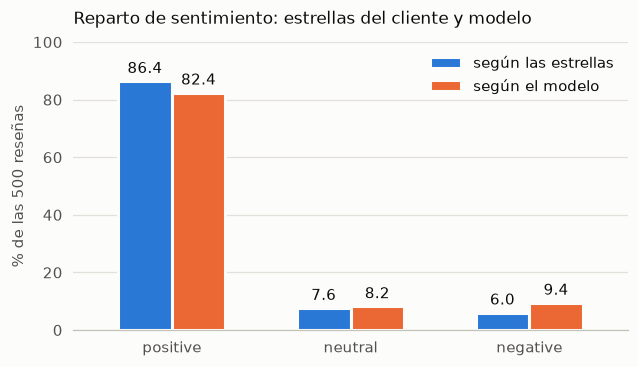

In [13]:
results["rating_sentiment"] = results["rating"].map(STARS_TO_SENTIMENT)

STARS_COL, MODEL_COL = "según las estrellas (%)", "según el modelo (%)"
breakdown = pd.DataFrame({
    "reseñas (estrellas)": results["rating_sentiment"].value_counts().reindex(BANDS),
    "reseñas (modelo)": results["sentiment"].value_counts().reindex(BANDS),
})
breakdown[STARS_COL] = (breakdown["reseñas (estrellas)"] / len(results) * 100).round(1)
breakdown[MODEL_COL] = (breakdown["reseñas (modelo)"] / len(results) * 100).round(1)
breakdown["diferencia (puntos)"] = (breakdown[MODEL_COL] - breakdown[STARS_COL]).round(1)
breakdown.index.name = "banda"
display(breakdown)

print(f"Media del negocio: {BUSINESS_AVERAGE} | media de las estrellas del dataset: {results['rating'].mean():.2f} | "
      f"media de las estrellas predichas: {results['predicted_stars'].mean():.2f}")

ax = breakdown[[STARS_COL, MODEL_COL]].plot.bar(
    color=[BLUE, ORANGE], width=0.6, rot=0, figsize=(6.5, 3.4), edgecolor=SURFACE, linewidth=2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)
ax.grid(axis="x", visible=False)
ax.set(title="Reparto de sentimiento: estrellas del cliente y modelo", xlabel="", ylabel="% de las 500 reseñas", ylim=(0, 100))
ax.legend(["según las estrellas", "según el modelo"], frameon=False)
plt.show()

El modelo lee como positivas el **82,4 %** de las reseñas, como neutrales el **8,2 %** y como negativas el **9,4 %**. Es un reparto propio de un negocio muy bien valorado y cercano al de las estrellas, pero algo más duro: 4 puntos menos de positivas y 3,4 puntos más de negativas, y una media predicha de 4,40 frente a 4,50.

Para ver de dónde salen esos puntos cruzamos, reseña a reseña, lo que puso el cliente con lo que predice el modelo.

In [14]:
display(pd.crosstab(results["rating"], results["predicted_stars"], margins=True))
display(pd.crosstab(results["rating_sentiment"], results["sentiment"], margins=True).reindex(index=BANDS + ["All"], columns=BANDS + ["All"]))

same_band = results["rating_sentiment"] == results["sentiment"]
same_stars = results["rating"] == results["predicted_stars"]
print(f"Misma banda: {same_band.sum()} de {len(results)} ({same_band.mean():.1%}) | mismas estrellas exactas: {same_stars.mean():.1%}")

predicted_stars,1,2,3,4,5,All
rating,,,,,,
1,3,9,0,0,0,12
2,7,9,2,0,0,18
3,0,3,35,0,0,38
4,1,0,3,47,21,72
5,11,4,1,9,335,360
All,22,25,41,56,356,500


sentiment,positive,neutral,negative,All
rating_sentiment,,,,
positive,412,4,16,432
neutral,0,35,3,38
negative,0,2,28,30
All,412,41,47,500


Misma banda: 475 de 500 (95.0%) | mismas estrellas exactas: 85.8%


En 475 de las 500 reseñas (95,0 %) la banda del modelo coincide con la de las estrellas. Los 25 desacuerdos van casi todos en la misma dirección: en 23 el modelo es más duro que el cliente y solo en 2 es más blando (dos reseñas de 2 estrellas que lee como neutrales). Ninguna reseña con 1–3 estrellas se lee como positiva.

La diferencia con las estrellas sale, por tanto, de un grupo concreto: **16 reseñas con 4–5 estrellas que el modelo marca como negativas** y otras 4 que deja en neutral. Las miramos de cerca.

## 6. Falsos negativos

Llamamos falso negativo a una reseña con 4–5 estrellas del cliente a la que el modelo da 1–2 estrellas. Son estas 16:

In [15]:
positive_rated = results[results["rating"] >= 4]
false_negatives = positive_rated[positive_rated["predicted_stars"] <= 2]

print(f"Falsos negativos: {len(false_negatives)} de {len(positive_rated)} reseñas con 4-5 estrellas ({len(false_negatives) / len(positive_rated):.1%})")
false_negatives[["review_id", "rating", "predicted_stars", "confidence", "review_text"]]

Falsos negativos: 16 de 432 reseñas con 4-5 estrellas (3.7%)


,review_id,rating,predicted_stars,confidence,review_text
13,14,4,1,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,0.2679,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,0.3247,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,0.2751,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.3492,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit."
253,254,5,1,0.3641,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1,0.4091,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1,0.6077,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


Leídas una a una, las 16 son positivas: elogian la comida, el trato o el ambiente y casi todas dicen que van a volver. Dos de ellas (204 y 322) incluyen una queja, pero la propia reseña la descarta («the food made up for it»).

Un primer rasgo común es la confianza: el modelo duda en estas predicciones mucho más que en el resto.

In [16]:
agreement = (results["rating_sentiment"] == results["sentiment"]).map({True: "coincide", False: "no coincide"})
print(f"Confianza mediana: falsos negativos {false_negatives['confidence'].median():.2f} | todas las reseñas {results['confidence'].median():.2f}")

confidence_group = (results["confidence"] >= 0.5).map({True: "confianza >= 0.5", False: "confianza < 0.5"}).rename("confianza del modelo")
pd.crosstab(confidence_group, agreement.rename("banda del modelo frente a estrellas"), margins=True)

Confianza mediana: falsos negativos 0.36 | todas las reseñas 0.70


banda del modelo frente a estrellas,coincide,no coincide,All
confianza del modelo,,,
confianza < 0.5,51,22,73
confianza >= 0.5,424,3,427
All,475,25,500


Casi todos los desacuerdos (22 de 25) están entre las 73 predicciones con confianza inferior a 0,5. Por encima de ese umbral el modelo solo discrepa de las estrellas en 3 de 427 reseñas.

El segundo rasgo está en el texto. Comparamos qué frases aparecen en los falsos negativos y con qué frecuencia aparecen en el conjunto de reseñas de 4–5 estrellas.

In [17]:
def sentence_share(frame):
    return frame["review_text"].apply(split_sentences).explode().value_counts() / len(frame) * 100


shared = pd.DataFrame({
    "% de los falsos negativos": sentence_share(false_negatives),
    "% de las reseñas de 4-5 estrellas": sentence_share(positive_rated),
}).dropna().round(1)
shared.sort_values("% de los falsos negativos", ascending=False).head(6)

,% de los falsos negativos,% de las reseñas de 4-5 estrellas
review_text,,
Every dish was bursting with flavor.,75.0,9.5
Already planning my next visit.,68.8,17.4
Tried Harbor House Café after seeing it recommended online.,37.5,15.7
Stopped by Harbor House Café for the first time.,37.5,14.1
Will definitely be back!,25.0,19.7
They went out of their way to accommodate my allergy.,25.0,8.8


«Every dish was bursting with flavor.» está en 12 de los 16 falsos negativos y en menos del 10 % de las reseñas positivas. Los otros 4 llevan «They went out of their way to accommodate my allergy.». Como el texto está hecho de frases repetidas, podemos pasar cada una de las 69 frases por el modelo, sola, y quedarnos con las que puntúa con 1–2 estrellas. Al lado ponemos la puntuación media de las reseñas en las que aparece cada frase.

In [18]:
unique_sentences = sentences.value_counts()
distributions = classifier(unique_sentences.index.tolist(), batch_size=32, top_k=None)
probabilities = [{int(item["label"].split()[0]): item["score"] for item in distribution} for distribution in distributions]

# Puntuación media que ponen los clientes a las reseñas que contienen cada frase.
sentence_rating = reviews["rating"].loc[sentences.index].groupby(sentences.values).mean()

sentence_scores = pd.DataFrame({
    "frase": unique_sentences.index,
    "apariciones": unique_sentences.values,
    "rating medio de sus reseñas": sentence_rating.reindex(unique_sentences.index).round(2).values,
    "estrellas según el modelo": [max(p, key=p.get) for p in probabilities],
    "P(1-2 estrellas)": [round(p[1] + p[2], 2) for p in probabilities],
})
read_as_negative = sentence_scores[sentence_scores["estrellas según el modelo"] <= 2]

print(f"Frases que el modelo puntúa con 1-2 estrellas: {len(read_as_negative)} de {len(sentence_scores)}")
read_as_negative.sort_values("rating medio de sus reseñas", ascending=False).head(8)

Frases que el modelo puntúa con 1-2 estrellas: 22 de 69


,frase,apariciones,rating medio de sus reseñas,estrellas según el modelo,P(1-2 estrellas)
27,They went out of their way to accommodate my allergy.,38,5.00,1,0.78
67,"Nobody checked on us the entire meal, but honestly the food made up for it.",2,5.00,2,0.55
22,Every dish was bursting with flavor.,41,4.68,1,0.94
4,Tried Harbor House Café after seeing it recommended online.,76,4.57,1,0.73
8,Stopped by Harbor House Café for the first time.,70,4.56,1,0.88
32,Might give it another shot.,23,3.30,1,0.64
58,The staff seemed annoyed to be there.,5,2.20,2,0.62
44,Our server got our order wrong twice.,10,2.10,1,0.86


De las 22 frases que el modelo puntúa con 1–2 estrellas, 17 aparecen en reseñas tibias o negativas: son quejas de verdad o frases tibias como «Might give it another shot.». Las otras cinco aparecen en reseñas con una media de más de 4,5 estrellas:

- dos elogios: «Every dish was bursting with flavor.» y «They went out of their way to accommodate my allergy.»;
- dos frases de contexto, sin opinión: «Stopped by Harbor House Café for the first time.» y «Tried Harbor House Café after seeing it recommended online.»;
- una frase mixta que sí contiene una queja («Nobody checked on us the entire meal, but honestly the food made up for it.») y que solo está en 2 reseñas.

Dos pruebas rápidas para confirmar que el problema son los dos elogios. La primera: decir lo mismo con otras palabras.

In [19]:
probes = [
    "Every dish was bursting with flavor.",
    "Every dish was full of flavor.",
    "They went out of their way to accommodate my allergy.",
    "They were happy to accommodate my allergy.",
]
pd.DataFrame({"frase": probes, "estrellas predichas": [int(output["label"].split()[0]) for output in classifier(probes)]})

,frase,estrellas predichas
0,Every dish was bursting with flavor.,1
1,Every dish was full of flavor.,5
2,They went out of their way to accommodate my allergy.,1
3,They were happy to accommodate my allergy.,5


Con «full of flavor» o «were happy to» el modelo da 5 estrellas: no falla por el tema (comida, alergias) sino por la expresión. La segunda prueba: quitar esos dos elogios de los 16 falsos negativos y volver a clasificar lo que queda.

In [20]:
MISREAD_PRAISE = [
    "Every dish was bursting with flavor.",
    "They went out of their way to accommodate my allergy.",
]


def without_misread_praise(review):
    return " ".join(sentence for sentence in split_sentences(review) if sentence not in MISREAD_PRAISE)


ablated = classifier(false_negatives["review_text"].apply(without_misread_praise).tolist(), batch_size=32)
ablation = false_negatives[["review_id", "rating", "predicted_stars"]].copy()
ablation["predicted_stars sin la frase"] = [int(output["label"].split()[0]) for output in ablated]

print(f"Pasan a 4-5 estrellas al quitar la frase: {(ablation['predicted_stars sin la frase'] >= 4).sum()} de {len(ablation)}")
ablation.T

Pasan a 4-5 estrellas al quitar la frase: 16 de 16


,13,14,72,86,137,199,203,253,269,321,331,408,439,461,473,488
review_id,14,15,73,87,138,200,204,254,270,322,332,409,440,462,474,489
rating,4,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
predicted_stars,1,1,1,1,2,2,1,1,1,1,1,1,2,2,1,1
predicted_stars sin la frase,4,5,5,5,4,5,4,5,5,4,5,4,4,4,5,5


Las 16 pasan a positivas. Queda por explicar por qué la mayoría de reseñas con esas frases sí se clasifican bien: contamos, en cada reseña de 4–5 estrellas, cuántas lleva de las cuatro frases sin queja que el modelo lee como negativas (los dos elogios y las dos de contexto).

In [21]:
MISREAD_SENTENCES = MISREAD_PRAISE + [
    "Stopped by Harbor House Café for the first time.",
    "Tried Harbor House Café after seeing it recommended online.",
]

misread_count = positive_rated["review_text"].apply(lambda review: sum(s in MISREAD_SENTENCES for s in split_sentences(review)))
by_count = positive_rated.assign(is_false_negative=positive_rated["predicted_stars"] <= 2).groupby(misread_count.rename("frases mal leídas en la reseña"))["is_false_negative"].agg(["size", "sum"])
by_count.columns = ["reseñas de 4-5 estrellas", "falsos negativos"]
by_count["% falsos negativos"] = (by_count["falsos negativos"] / by_count["reseñas de 4-5 estrellas"] * 100).round(1)
by_count

,reseñas de 4-5 estrellas,falsos negativos,% falsos negativos
frases mal leídas en la reseña,,,
0,250,0,0.0
1,156,4,2.6
2,26,12,46.2


El error aparece por acumulación. Sin ninguna de esas frases no hay ni un falso negativo en 250 reseñas; con una, el resto de elogios suele compensar (4 de 156); con dos, casi la mitad de las reseñas acaba marcada como negativa (12 de 26).

**Hipótesis.** Lo que las pruebas dejan establecido es *qué* frases provocan el error. El *porqué* es una hipótesis, coherente con el aviso del encargo sobre el desajuste de dominio: el modelo aprendió de reseñas de productos y arrastra asociaciones de ese mundo.

- «bursting» y «went out of their way» son elogios en hostelería. En reseñas de productos, algo que revienta (una costura, un envase) o tener que desviarse suele aparecer en quejas, y «allergy» va ligada a reacciones a un producto. El modelo se queda con esa lectura literal.
- «for the first time» y «after seeing it recommended online» son contexto neutro, pero en una reseña de producto suelen preceder a una decepción («lo compré porque lo recomendaban y…»).
- El modelo puntúa la reseña entera: basta con que coincidan dos de estas frases en un texto de tres o cuatro para que pesen más que el resto.

No son errores al azar ni reflejan clientes descontentos: son frases concretas, repetidas, que un modelo de reseñas de productos lee al revés.

Quedan 4 reseñas con 4–5 estrellas que el modelo deja en neutral. Son reseñas mixtas del insight 5:

In [22]:
positive_rated[positive_rated["predicted_stars"] == 3][["review_id", "rating", "predicted_stars", "confidence", "review_text"]]

,review_id,rating,predicted_stars,confidence,review_text
146,147,4,3,0.4790,"Stopped by Harbor House Café for the first time. The seasonal menu never disappoints. Service was fine, nothing memorable, but overall a solid experience. Might give it another shot."
252,253,4,3,0.2553,"Stopped by Harbor House Café for the first time. Every dish was bursting with flavor. Average service, no complaints, but overall a solid experience. This is now my go-to spot."
463,464,4,3,0.4725,"Regular customer at Harbor House Café here. Every dish was bursting with flavor. Service was fine, nothing memorable, but overall a solid experience. Already planning my next visit."
476,477,5,3,0.2709,"Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. We waited 25 minutes just to get water, but honestly the food made up for it. Already planning my next visit."


Aquí el desacuerdo es más discutible: el cliente matiza el servicio (normal sin más, o una espera larga) y aun así pone 4–5 estrellas; el modelo promedia y se queda en 3. Las cuatro llevan además alguna de las frases que el modelo lee mal. Lo anotamos como límite del modelo con reseñas mixtas, no como error claro.

Si corregimos solo los 16 falsos negativos, que leídos a mano son positivos, el reparto queda así:

In [23]:
is_false_negative = (results["rating"] >= 4) & (results["predicted_stars"] <= 2)
corrected = results["sentiment"].mask(is_false_negative, "positive")

comparison = pd.DataFrame({
    "según las estrellas (%)": results["rating_sentiment"].value_counts(normalize=True).reindex(BANDS) * 100,
    "modelo (%)": results["sentiment"].value_counts(normalize=True).reindex(BANDS) * 100,
    "modelo con los 16 falsos negativos corregidos (%)": corrected.value_counts(normalize=True).reindex(BANDS) * 100,
}).round(1)
comparison

,según las estrellas (%),modelo (%),modelo con los 16 falsos negativos corregidos (%)
positive,86.4,82.4,85.6
neutral,7.6,8.2,8.2
negative,6.0,9.4,6.2


## 7. Muestra revisada a mano

Los totales cuadran con las estrellas, pero conviene leer predicciones concretas. Sacamos 18 reseñas, 6 por cada banda que asigna el modelo y con semilla fija; así la muestra no se llena de reseñas de 5 estrellas, que son la gran mayoría. Cada una está leída y anotada a mano: la columna `lectura manual` es la banda que le pondríamos nosotros leyendo solo el texto.

In [24]:
sample = results.groupby("sentiment").sample(n=6, random_state=42).sort_values(["sentiment", "review_id"])

MANUAL_REVIEW = {
    206: ("negative", "Huevos fríos, cajero maleducado y decepción final. Tiene sentido."),
    218: ("negative", "Bollería rancia, 25 minutos de espera y «disappointing». Tiene sentido."),
    223: ("negative", "Tres quejas seguidas y no lo recomienda. Banda correcta; el cliente puso 1 estrella y el modelo 2."),
    342: ("negative", "Café quemado, nadie atendió la mesa, local caótico. Banda correcta; el cliente puso 1 estrella y el modelo 2."),
    440: ("positive", "Etiqueta incorrecta. Cliente habitual que elogia comida, servicio y precio y piensa volver. Lleva «bursting with flavor»."),
    474: ("positive", "Etiqueta incorrecta. Primera visita y todo son elogios («my go-to spot»). Lleva «bursting with flavor» y «for the first time»."),
    9: ("neutral", "Tibia: bocadillos del montón y personal educado pero lento. Tiene sentido."),
    233: ("neutral", "«The coffee was okay», «might give it another shot». Tiene sentido."),
    313: ("neutral", "Mismo tono tibio que la 9. Tiene sentido."),
    362: ("neutral", "Ni quejas ni elogios. Tiene sentido."),
    407: ("neutral", "«Decent, nothing special». Tiene sentido."),
    416: ("neutral", "Café normal y servicio lento pero educado. Tiene sentido."),
    7: ("positive", "Elogios y recomendación explícita. Tiene sentido."),
    96: ("positive", "Positiva con un servicio «nothing memorable»; las 4 estrellas reflejan lo que dice el texto."),
    231: ("positive", "Tiene sentido. Lleva la frase de la alergia, pero el resto de elogios la compensa."),
    366: ("positive", "Cliente habitual satisfecho. Tiene sentido."),
    376: ("positive", "Positiva con una queja por la espera. El modelo acierta la banda, con poca confianza (0,41)."),
    467: ("positive", "Banda correcta, pero el modelo da 5 estrellas muy seguro y el cliente puso 4: la espera de 25 minutos no le pesa frente a «Five stars without hesitation»."),
}
assert set(sample["review_id"]) == set(MANUAL_REVIEW), "La muestra ha cambiado: hay que volver a anotarla."

manual = sample[["review_id", "review_text", "rating", "predicted_stars", "sentiment", "confidence"]].copy()
manual["lectura manual"] = manual["review_id"].map(lambda review_id: MANUAL_REVIEW[review_id][0])
manual["nota"] = manual["review_id"].map(lambda review_id: MANUAL_REVIEW[review_id][1])

agrees = manual["lectura manual"] == manual["sentiment"]
print(f"La etiqueta del modelo coincide con la lectura manual en {agrees.sum()} de {len(manual)} reseñas")
manual

La etiqueta del modelo coincide con la lectura manual en 16 de 18 reseñas


,review_id,review_text,rating,predicted_stars,sentiment,confidence,lectura manual,nota
205,206,Came to Harbor House Café for a birthday brunch. My eggs came out cold. The cashier was rude when i asked about the menu. Expected a lot more given the reviews.,2,2,negative,0.3553,negative,"Huevos fríos, cajero maleducado y decepción final. Tiene sentido."
217,218,Regular customer at Harbor House Café here. The pastry was stale. We waited 25 minutes just to get water. Disappointing experience overall.,2,2,negative,0.6084,negative,"Bollería rancia, 25 minutos de espera y «disappointing». Tiene sentido."
222,223,Came to Harbor House Café for a birthday brunch. The pastry was stale. The cashier was rude when i asked about the menu. Tables were sticky and the floor hadn't been swept. Probably won't recommend it to friends.,1,2,negative,0.5297,negative,Tres quejas seguidas y no lo recomienda. Banda correcta; el cliente puso 1 estrella y el modelo 2.
341,342,Regular customer at Harbor House Café here. The coffee tasted burnt. Nobody checked on us the entire meal. The place felt cramped and chaotic. Expected a lot more given the reviews.,1,2,negative,0.5082,negative,"Café quemado, nadie atendió la mesa, local caótico. Banda correcta; el cliente puso 1 estrella y el modelo 2."
439,440,Regular customer at Harbor House Café here. Every dish was bursting with flavor. Our server remembered our names by the second visit. Reasonably priced for the quality. Already planning my next visit.,5,2,negative,0.3241,positive,"Etiqueta incorrecta. Cliente habitual que elogia comida, servicio y precio y piensa volver. Lleva «bursting with flavor»."
473,474,Stopped by Harbor House Café for the first time. Every dish was bursting with flavor. Service was fast and friendly. This is now my go-to spot.,5,1,negative,0.4817,positive,Etiqueta incorrecta. Primera visita y todo son elogios («my go-to spot»). Lleva «bursting with flavor» y «for the first time».
8,9,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop.",3,3,neutral,0.6470,neutral,Tibia: bocadillos del montón y personal educado pero lento. Tiene sentido.
232,233,Stopped by Harbor House Café for the first time. The coffee was okay. The staff were polite but a bit slow. Might give it another shot.,3,3,neutral,0.6899,neutral,"«The coffee was okay», «might give it another shot». Tiene sentido."
312,313,"Tried Harbor House Café after seeing it recommended online. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop.",3,3,neutral,0.6531,neutral,Mismo tono tibio que la 9. Tiene sentido.
361,362,"Stopped by Harbor House Café for the first time. The coffee was okay. Average service, no complaints. It's fine for a quick stop.",3,3,neutral,0.7697,neutral,Ni quejas ni elogios. Tiene sentido.


En 16 de las 18 reseñas la etiqueta del modelo tiene sentido. Las dos que no (440 y 474) son falsos negativos del patrón de la sección 6: reseñas claramente positivas con «bursting with flavor». En las bandas neutral y positiva no encontramos ninguna etiqueta incorrecta.

Dos matices que la banda esconde: en las negativas el modelo tiende a dar 2 estrellas donde el cliente puso 1, y en la 467 ignora una queja real porque el texto termina con «Five stars without hesitation». Para la pregunta de la account manager, que es por bandas, ninguno de los dos cambia el resultado.

## 8. Paso a producción: `src/app.py`

El notebook cuenta la historia; la ruta de inferencia limpia está en `src/app.py`. Usa el mismo modelo y la misma revisión, lo carga una sola vez, aplica el mismo mapeo y escribe `data/processed/reviews_with_sentiment.csv`. Lo ejecutamos desde aquí y comprobamos que su salida coincide con las predicciones de este notebook.

In [25]:
import subprocess
import sys

run = subprocess.run([sys.executable, "app.py"], capture_output=True, text=True, check=True)
print(run.stdout)

production = pd.read_csv("../data/processed/reviews_with_sentiment.csv")
assert production["review_id"].tolist() == results["review_id"].tolist()
assert production["predicted_stars"].tolist() == results["predicted_stars"].tolist()
assert production["sentiment"].tolist() == results["sentiment"].tolist()

print(f"{len(production)} filas, con las mismas estrellas y bandas que el notebook")
print(f"Columnas: {list(production.columns)}")

Modelo: nlptown/bert-base-multilingual-uncased-sentiment@8f6f4e3a
Reseñas procesadas: 500
  positive  82.4 %
  neutral    8.2 %
  negative   9.4 %
Salida: data/processed/reviews_with_sentiment.csv

500 filas, con las mismas estrellas y bandas que el notebook
Columnas: ['review_id', 'rating', 'review_text', 'predicted_stars', 'sentiment', 'confidence']


## 9. Conclusiones

**Respuesta corta:** sí, lo que escriben los clientes es coherente con el 4,5. No hay un descontento escondido detrás de la media.

**Cuántas reseñas se leen como positivas, neutrales o negativas**

| | Positivas | Neutrales | Negativas |
| --- | --- | --- | --- |
| Según las estrellas que puso cada cliente | 86,4 % (432) | 7,6 % (38) | 6,0 % (30) |
| Según el modelo, tal cual | 82,4 % (412) | 8,2 % (41) | 9,4 % (47) |
| Modelo con los 16 errores identificados corregidos | 85,6 % (428) | 8,2 % (41) | 6,2 % (31) |

**¿Coincide con el promedio de 4,5?** Sí. Unas 5 de cada 6 reseñas se leen como positivas, que es lo que corresponde a un negocio de 4,5 estrellas. El modelo y las estrellas ponen la misma etiqueta en 475 de las 500 reseñas (95 %).

**De dónde viene la diferencia.** El modelo, tal cual, da 4 puntos menos de reseñas positivas y 3,4 más de negativas que las estrellas. Esa diferencia no está en los clientes sino en el modelo: marca como negativas 16 reseñas que tienen 4–5 estrellas y que, leídas, son claramente positivas. Todas llevan una de dos expresiones elogiosas («bursting with flavor», «went out of their way to accommodate my allergy») que un modelo entrenado con reseñas de productos interpreta al revés. Al quitar esas frases, las 16 pasan a positivas. Corregidas, el reparto queda en 85,6 / 8,2 / 6,2 %, prácticamente el de las estrellas.

**Qué merece la pena contarle al cliente**

- Una media de 4,5 convive con 68 reseñas (casi 1 de cada 7) de 3 estrellas o menos.
- Entre las 432 reseñas positivas, 90 (1 de cada 5) llevan un «pero», y siempre es sobre el servicio: en 61 hay una queja clara (esperas, lentitud, trato, pedidos equivocados) y en 29 un servicio «sin más». Ninguna de esas pegas es sobre la comida.

**Cómo usar las etiquetas**

- Para el reparto global por bandas son fiables. Cuando el modelo se equivoca es por severo: ninguna reseña con 1–3 estrellas aparece como positiva.
- Para leer reseña a reseña, conviene revisar a mano las 73 predicciones con confianza inferior a 0,5 (ahí están 22 de los 25 desacuerdos con las estrellas) y, en particular, las negativas con 4–5 estrellas.
- El resultado por reseña está en `data/processed/reviews_with_sentiment.csv`, con estrellas predichas, banda y confianza.

**Límites**

- Tomamos las estrellas como referencia de lo que el cliente quiso decir; en la muestra leída a mano coinciden con el texto.
- Estas 500 reseñas combinan solo 69 frases. Con texto más libre aparecerán expresiones que aquí no hemos visto, así que la revisión manual de una muestra debería repetirse con cada entrega.
- Qué frases provocan el error está comprobado; por qué el modelo las lee así (el desajuste entre reseñas de productos y de servicio) es una hipótesis.

## Anexo: ¿mejoraría el resultado con otro modelo?

Extensión opcional del encargo. Repetimos la inferencia sobre las mismas 500 reseñas con `tabularisai/multilingual-sentiment-analysis`, también fijado por revisión. Devuelve cinco etiquetas, de «Very Negative» a «Very Positive», que llevamos a la escala de 1 a 5 y a las mismas bandas.

In [26]:
ALT_MODEL_ID = "tabularisai/multilingual-sentiment-analysis"
ALT_MODEL_REVISION = "eea032081f8d247b4303ef3565e7cec1b6f201c9"
ALT_LABEL_TO_STARS = {"Very Negative": 1, "Negative": 2, "Neutral": 3, "Positive": 4, "Very Positive": 5}

alt_classifier = pipeline("text-classification", model=ALT_MODEL_ID, revision=ALT_MODEL_REVISION, device=-1)
alt_outputs = alt_classifier(text.tolist(), batch_size=32, truncation=True)

results["alt_stars"] = [ALT_LABEL_TO_STARS[output["label"]] for output in alt_outputs]
results["alt_sentiment"] = results["alt_stars"].map(STARS_TO_SENTIMENT)
results[["review_id", "rating", "predicted_stars", "sentiment", "alt_stars", "alt_sentiment"]].head(3)

,review_id,rating,predicted_stars,sentiment,alt_stars,alt_sentiment
0,1,5,5,positive,4,positive
1,2,5,5,positive,4,positive
2,3,5,5,positive,3,neutral


Comparamos los dos modelos con las mismas medidas que usamos en las secciones 5 y 6.

,según las estrellas,nlptown,tabularisai
banda (%),,,
positive,86.4,82.4,88.8
neutral,7.6,8.2,2.2
negative,6.0,9.4,9.0


,nlptown,tabularisai
misma banda que las estrellas (de 500),475,453
falsos negativos: 4-5 estrellas leídas como negativas (de 432),16,7
reseñas de 1-3 estrellas leídas como positivas (de 68),0,25
reseñas de 3 estrellas leídas como neutrales (de 38),35,5


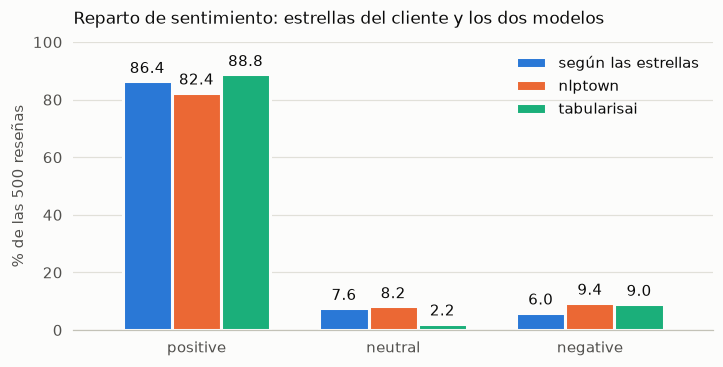

In [27]:
def model_summary(band_column):
    bands = results[band_column]
    return {
        "misma banda que las estrellas (de 500)": (bands == results["rating_sentiment"]).sum(),
        "falsos negativos: 4-5 estrellas leídas como negativas (de 432)": ((results["rating"] >= 4) & (bands == "negative")).sum(),
        "reseñas de 1-3 estrellas leídas como positivas (de 68)": ((results["rating"] <= 3) & (bands == "positive")).sum(),
        "reseñas de 3 estrellas leídas como neutrales (de 38)": ((results["rating"] == 3) & (bands == "neutral")).sum(),
    }


shares = pd.DataFrame({
    "según las estrellas": results["rating_sentiment"].value_counts(normalize=True).reindex(BANDS) * 100,
    "nlptown": results["sentiment"].value_counts(normalize=True).reindex(BANDS) * 100,
    "tabularisai": results["alt_sentiment"].value_counts(normalize=True).reindex(BANDS) * 100,
}).round(1)
shares.index.name = "banda (%)"
display(shares)

model_comparison = pd.DataFrame({"nlptown": model_summary("sentiment"), "tabularisai": model_summary("alt_sentiment")})
display(model_comparison)

ax = shares.plot.bar(color=[BLUE, ORANGE, AQUA], width=0.75, rot=0, figsize=(7.5, 3.4), edgecolor=SURFACE, linewidth=2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)
ax.grid(axis="x", visible=False)
ax.set(title="Reparto de sentimiento: estrellas del cliente y los dos modelos", xlabel="", ylabel="% de las 500 reseñas", ylim=(0, 100))
ax.legend(frameon=False)
plt.show()

La tasa de falsos negativos baja: de 16 a 7 reseñas (del 3,7 % al 1,6 % de las reseñas con 4–5 estrellas). A cambio, el segundo modelo casi no usa la banda neutral y lee como positivas 25 reseñas con 1–3 estrellas, algo que `nlptown` no hace nunca. En conjunto coincide menos con las estrellas: 453 reseñas en la misma banda (90,6 %) frente a 475 (95,0 %).

¿Qué reseñas siguen fallando?

In [28]:
alt_false_negatives = results[(results["rating"] >= 4) & (results["alt_stars"] <= 2)]
fixed = is_false_negative & (results["alt_stars"] >= 4)

print(f"Falsos negativos de nlptown que el segundo modelo lee como positivos: {fixed.sum()} de {is_false_negative.sum()}")
print(f"Falsos negativos del segundo modelo: {len(alt_false_negatives)}; "
      f"con la frase de la alergia: {alt_false_negatives['review_text'].str.contains('accommodate my allergy').sum()}")
alt_false_negatives[["review_id", "rating", "predicted_stars", "alt_stars", "review_text"]]

Falsos negativos de nlptown que el segundo modelo lee como positivos: 15 de 16
Falsos negativos del segundo modelo: 7; con la frase de la alergia: 7


,review_id,rating,predicted_stars,alt_stars,review_text
138,139,5,5,2,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. They went out of their way to accommodate my allergy. Five stars without hesitation.
219,220,5,5,2,Visited Harbor House Café last weekend. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.
230,231,5,5,2,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. This is now my go-to spot.
253,254,5,1,2,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
289,290,5,5,2,Grabbed a quick coffee at Harbor House Café this morning. Best brunch i've had in months. They went out of their way to accommodate my allergy. Five stars without hesitation.
351,352,5,5,1,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. Five stars without hesitation.
414,415,5,5,2,Came to Harbor House Café for a birthday brunch. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.


El segundo modelo corrige 15 de los 16 falsos negativos de `nlptown` (ya no tropieza con «bursting with flavor»), pero sus 7 falsos negativos llevan todos «They went out of their way to accommodate my allergy.», la otra frase que `nlptown` leía mal. El desajuste de dominio no desaparece: cambia de frase.

El problema nuevo está en las reseñas tibias. Así reparte cada modelo las reseñas según las estrellas del cliente:

In [29]:
display(pd.crosstab(results["rating"], results["sentiment"].rename("nlptown"))[BANDS])
display(pd.crosstab(results["rating"], results["alt_sentiment"].rename("tabularisai"))[BANDS])

lukewarm_as_positive = results[(results["rating"] == 3) & (results["alt_sentiment"] == "positive")]
lukewarm_as_positive[["review_id", "rating", "predicted_stars", "alt_stars", "review_text"]].head(3)

nlptown,positive,neutral,negative
rating,,,
1,0,0,12
2,0,2,16
3,0,35,3
4,68,3,1
5,344,1,15


tabularisai,positive,neutral,negative
rating,,,
1,0,0,12
2,1,0,17
3,24,5,9
4,69,3,0
5,350,3,7


,review_id,rating,predicted_stars,alt_stars,review_text
8,9,3,3,4,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop."
22,23,3,3,4,Regular customer at Harbor House Café here. The menu is fine but a bit repetitive. The staff were polite but a bit slow. It's fine for a quick stop.
24,25,3,3,4,"Visited Harbor House Café last weekend. The coffee was okay. Service was fine, nothing memorable. Might give it another shot."


De las 38 reseñas de 3 estrellas, `nlptown` deja 35 en neutral; el segundo modelo solo 5, y pasa 24 a positivas y 9 a negativas. Reseñas como la 25 («The coffee was okay. Service was fine, nothing memorable. Might give it another shot.») le parecen positivas.

Una última cuenta: usar el segundo modelo no como sustituto sino como segundo lector, y mirar dónde discrepan.

In [30]:
models_disagree = results["sentiment"] != results["alt_sentiment"]
nlptown_wrong = results["sentiment"] != results["rating_sentiment"]

print(f"Reseñas en las que los dos modelos dan bandas distintas: {models_disagree.sum()} de {len(results)}")
print(f"Falsos negativos de nlptown dentro de ese grupo: {(is_false_negative & models_disagree).sum()} de {is_false_negative.sum()}")
print(f"Desacuerdos de nlptown con las estrellas dentro de ese grupo: {(nlptown_wrong & models_disagree).sum()} de {nlptown_wrong.sum()}")

Reseñas en las que los dos modelos dan bandas distintas: 64 de 500
Falsos negativos de nlptown dentro de ese grupo: 15 de 16
Desacuerdos de nlptown con las estrellas dentro de ese grupo: 22 de 25


### Recomendación

**No cambiaríamos de modelo para este cliente.** Mantendríamos `nlptown` para el informe y usaríamos el segundo modelo, como mucho, de contraste.

- **Para la pregunta de la account manager gana `nlptown`.** Lo que necesita es un reparto por bandas fiable frente al 4,5, y `nlptown` coincide con las estrellas en el 95,0 % de las reseñas frente al 90,6 % del segundo modelo.
- **El segundo modelo falla en la dirección que más preocupa.** Reduce los falsos negativos de 16 a 7, pero lee como positivas 25 reseñas de 1–3 estrellas y deja la banda neutral casi vacía (2,2 %). En un informe cuyo riesgo es dar una imagen mejor que la real, inflar las positivas es peor que quedarse corto: los 16 errores de `nlptown` son severos, están localizados y se corrigen a mano.
- **El desajuste de dominio sigue ahí.** Sus 7 falsos negativos comparten una frase que también confunde a `nlptown`. Cambiar de modelo mueve el problema, no lo resuelve.
- **Licencia.** La ficha del segundo modelo en Hugging Face indica CC BY-NC 4.0 (uso no comercial); la de `nlptown`, MIT. Antes de usarlo en un entregable para un cliente habría que aclarar ese punto.
- **Dónde sí aporta.** Como segundo lector: los dos modelos discrepan en 64 reseñas, y en ese grupo están 15 de los 16 falsos negativos y 22 de los 25 desacuerdos de `nlptown` con las estrellas. Revisar a mano esas 64 reseñas es una alternativa al corte por confianza de la sección 6.

Si el volumen de reseñas creciera y la revisión manual dejara de ser viable, el siguiente paso no sería este modelo sino buscar uno ajustado con reseñas de hostelería o servicios y repetir esta misma comparación.